In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [ ]:
df = pd.read_csv('/content/Std_dataset.csv')
print('Dataset loaded successfull')

Dataset loaded successfull


In [ ]:
df.shape

(300, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    int64  
 1   y       300 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 4.8 KB


In [ ]:
df.describe()

,x,y
count,300.000000,300.000000
mean,50.936667,51.205051
std,28.504286,29.071481
min,0.000000,-3.467884
25%,27.000000,25.676502
50%,53.000000,52.170557
75%,73.000000,74.303007
max,100.000000,105.591837


In [ ]:
#Missing Values
df.isnull().sum()

,0
x,0
y,0


In [ ]:
#Convert y to the nearest lower integer by removing decimal values
df['y_int'] = df['y'].apply(lambda x: int(x))
df

,x,y,y_int
0,77,79.775152,79
1,21,23.177279,23
2,22,25.609262,25
3,20,17.857388,17
4,36,41.849864,41
...,...,...,...
295,71,68.545888,68
296,46,47.334876,47
297,55,54.090637,54
298,62,63.297171,63


In [ ]:
# Independent variable
x = df[['x']]
x

,x
0,77
1,21
2,22
3,20
4,36
...,...
295,71
296,46
297,55
298,62


In [ ]:
# Dependent variable
y = df['y_int']
y

,y_int
0,79
1,23
2,25
3,17
4,41
...,...
295,68
296,47
297,54
298,63


In [ ]:
#Split the dataset into training and testing using the new x and y
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [ ]:
#Create the model
model = LinearRegression()

In [ ]:
#Train the Model
model.fit(x_train, y_train)
print("Model Trained")

Model Trained


In [ ]:
#Generate predictions for training and testing datasets using the trained model
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)
print("Predictions generated for both training and testing datasets")

Predictions generated for both training and testing datasets


In [ ]:
# Evaluations using different metrics

# Evaluate model performance on training data using MAE, MSE, RMSE, and R2 score
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_train_pred)
print("\nAfter model Training:")
print(f"Mean Absolute Error (MAE): {mae_train:.2f}")
print(f"Mean Squared Error (MSE): {mse_train:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_train:.2f}")
print(f"R2 Score: {r2_train:.2f}")


# Evaluate model performance on training data using MAE, MSE, RMSE, and R2 score
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_test_pred)
print("\nAfter model Testing:")
print(f"Mean Absolute Error (MAE): {mae_test:.2f}")
print(f"Mean Squared Error (MSE): {mse_test:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_test:.2f}")
print(f"R2 Score: {r2_test:.2f}")


After model Training:
Mean Absolute Error (MAE): 2.39
Mean Squared Error (MSE): 9.26
Root Mean Squared Error (RMSE): 3.04
R2 Score: 0.99

After model Testing:
Mean Absolute Error (MAE): 2.49
Mean Squared Error (MSE): 9.22
Root Mean Squared Error (RMSE): 3.04
R2 Score: 0.99


In [ ]:
#slope
model.coef_

array([1.01265539])

In [ ]:
#intercept
model.intercept_

np.float64(-0.77253416883255)

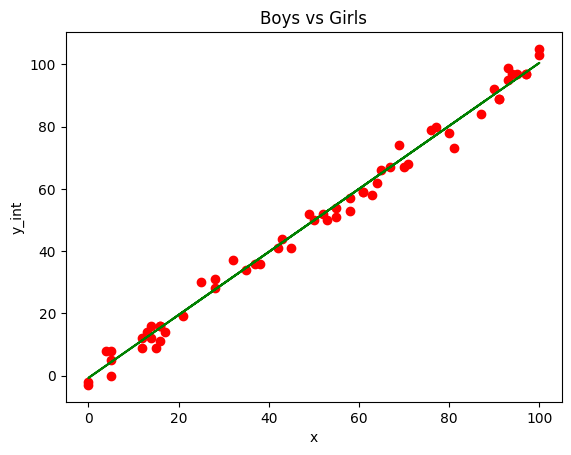

In [ ]:
#plot actual training datapoints and the fitted linear regression
plt.scatter(x_test, y_test, color='red')
plt.plot(x_train, model.predict(x_train), color='green')
plt.title('Boys vs Girls')
plt.xlabel('x')
plt.ylabel('y_int')
plt.show()

## Description

### 1. Business Understanding
**1.1 Problem Statement & Relevance:**
The problem addressed is to predict a continuous target variable `y` based on an independent variable `x` using a linear regression model. This is a fundamental machine learning task often used for forecasting or understanding relationships between variables.

**1.2 Expected Benefits:**
The developed linear regression model can provide insights into the linear relationship between `x` and `y_int`, allowing for predictions of `y` given new values of `x`. This can be beneficial for various applications requiring simple, interpretable predictive models.

### 2. Data Understanding
**2.1 Dataset Structure:**
- **Variables:** The dataset contains two primary variables: `x` (integer type) and `y` (float64 type). A new derived variable `y_int` (integer type) is created during preparation.
- **Shape:** The dataset consists of 300 entries (rows) and 2 original columns.
- **Target:** The target variable for prediction is `y_int` (derived from `y`).

**2.2 Data Dictionary:**
- `x`: An independent variable, likely a numerical feature, units and full form are not specified in the code but assumed to be a continuous quantity.
- `y`: A dependent variable, also a numerical feature, with floating-point values.
- `y_int`: An integer version of the `y` variable, created for modeling purposes.

**2.3 Data Quality Observations:**
- **Missing Values:** No missing values were found in the `x` or `y` columns of the dataset.
- **Summary Statistics:** Descriptive statistics (`df.describe()`) show the range, mean, and standard deviation for both `x` and `y`, indicating numerical distributions.

### 3. Data Preparation
**3.1 Cleaning Steps:**
- The primary cleaning step involves converting the floating-point `y` column into an integer column `y_int`, effectively truncating decimal values. This simplifies the target variable for the regression model.

**3.2 Feature Engineering:**
- A new column `y_int` was created from the existing `y` column. While simple, this transformation effectively serves as a form of feature engineering by altering the target variable's data type.

**3.3 Train/Test Split:**
- The dataset was split into training and testing sets to evaluate the model's generalization performance. 80% of the data was allocated for training (`x_train`, `y_train`) and 20% for testing (`x_test`, `y_test`), using `train_test_split` with `random_state = 42` for reproducibility.

### 4. Modelling
**4.1 Model Approach:**
- A `LinearRegression` model from `scikit-learn` was chosen. This model is suitable for establishing a linear relationship between a single independent variable (`x`) and a continuous dependent variable (`y_int`). It is known for its interpretability and efficiency.

**4.2 Model Training:**
- The `LinearRegression` model was initialized and then trained (`model.fit()`) using the prepared training data (`x_train` and `y_train`). During this process, the model determines the optimal slope (coefficient) and intercept that best fit the training data.

**4.3 Model Outputs & Interpretation:**
- The trained model provides a coefficient (`model.coef_`) and an intercept (`model.intercept_`), which define the linear equation `y_int = (coef_ * x) + intercept_`. These values represent the estimated linear relationship between `x` and `y_int`.

### 5. Evaluation
**5.1 Appropriate Metric Selection:**
- For evaluating the linear regression model, several standard regression metrics were used:
    - **Mean Absolute Error (MAE):** Measures the average magnitude of the errors in a set of predictions, without considering their direction. It's robust to outliers.
    - **Mean Squared Error (MSE):** Measures the average of the squares of the errors. It penalizes larger errors more heavily.
    - **Root Mean Squared Error (RMSE):** The square root of MSE, providing error in the same units as the target variable.
    - **R2 Score (Coefficient of Determination):** Represents the proportion of the variance in the dependent variable that is predictable from the independent variable(s). A higher R2 indicates a better fit.

**5.2 Interpretation:**
- The model's performance was evaluated on both training and testing datasets. High R2 scores (approximately 0.99 for both training and testing) indicate that the model explains a very large proportion of the variance in `y_int`.
- Low MAE, MSE, and RMSE values for both sets further suggest that the model makes accurate predictions, with small average errors.
- The similarity in metric values between the training and testing sets implies that the model generalizes well to unseen data and is not overfitting.

### 6. Conclusion
- A linear regression model was successfully developed and evaluated for predicting `y_int` from `x`. The model demonstrated excellent performance with high R2 scores and low error metrics on both training and testing datasets, indicating a strong linear relationship and good generalization capabilities.

### 7. Appendix
- **Plots:** A visualization of the linear regression model was generated, showing the actual test data points and the fitted regression line derived from the training data. This plot visually confirms the strong linear relationship captured by the model.